In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/workspaces/La_ventaja_de_ser_local_en_el_futbol/datos/home_advantage_matches.csv")

In [3]:
df.sample(10)

,match_id,league,elo_home,elo_away,elo_diff,crowd_present,stadium_capacity,attendance_pct,crowd_size,travel_distance_km,...,fouls_away,yellow_home,yellow_away,red_home,red_away,goals_home,goals_away,home_goal_diff,home_result,home_points
35886,MCH035886,EPL,1656,1350,306,1,30400,0.520,15800,80.0,...,11,2,2,0,0,1,1,0,draw,1
20149,MCH020149,Serie_A,1478,1459,19,1,47800,0.719,34300,590.0,...,19,4,4,0,0,2,1,1,home_win,3
46206,MCH046206,Eredivisie,1467,1368,99,1,30900,0.922,28500,340.0,...,15,1,4,0,0,1,1,0,draw,1
13019,MCH013019,Eredivisie,1730,1501,229,1,31700,0.200,6300,450.0,...,13,0,5,0,0,0,3,-3,away_win,0
41788,MCH041788,Primeira,1440,1351,89,1,32100,0.791,25400,180.0,...,12,0,3,0,1,1,3,-2,away_win,0
35101,MCH035101,Championship,1394,1676,-282,1,70900,0.882,62600,240.0,...,13,2,1,0,0,3,3,0,draw,1
4274,MCH004274,Serie_A,1678,1647,31,1,21600,0.879,19000,320.0,...,17,4,1,0,0,3,2,1,home_win,3
9749,MCH009749,Ligue_1,1492,1487,5,1,8000,0.666,5300,220.0,...,14,1,2,0,0,2,0,2,home_win,3
32135,MCH032135,Bundesliga,1409,1676,-267,1,59600,0.508,30300,150.0,...,17,4,4,0,0,2,2,0,draw,1
16291,MCH016291,Bundesliga,1406,1449,-43,1,38000,0.564,21400,250.0,...,11,1,3,0,1,4,1,3,home_win,3


In [4]:
df.isna().sum()

match_id                       0
league                         0
elo_home                       0
elo_away                       0
elo_diff                       0
crowd_present                  0
stadium_capacity               0
attendance_pct                 0
crowd_size                     0
travel_distance_km             0
timezones_crossed              0
is_derby                       0
venue_familiarity              0
referee_bias_susceptibility    0
fouls_home                     0
fouls_away                     0
yellow_home                    0
yellow_away                    0
red_home                       0
red_away                       0
goals_home                     0
goals_away                     0
home_goal_diff                 0
home_result                    0
home_points                    0
dtype: int64

In [5]:
# Esta base de datos no tiene datos faltantes
# Si existieran datos faltantes se reemplazarían de esta manera (variables numéricas):
df['travel_distance_km'] = df['travel_distance_km'].fillna(df['travel_distance_km'].median())


In [6]:
duplicados = df[df.duplicated()]
duplicados.shape

(0, 25)

In [7]:
# Si existieran duplicados se eliminarían así:
df = df.drop_duplicates()

In [8]:
ligas = list(df['league'].unique())
ligas

['Serie_A',
 'Primeira',
 'Eredivisie',
 'EPL',
 'La_Liga',
 'Championship',
 'Ligue_1',
 'Bundesliga']

In [9]:
resultados = list(df['home_result'].unique())
resultados

['draw', 'home_win', 'away_win']

In [10]:
# Si existieran valores inconsistentes en texto se reemplazarían así:
df['league'] = df['league'].replace({'LaLiga': 'La_Liga'})

In [11]:
df.sample(10)

,match_id,league,elo_home,elo_away,elo_diff,crowd_present,stadium_capacity,attendance_pct,crowd_size,travel_distance_km,...,fouls_away,yellow_home,yellow_away,red_home,red_away,goals_home,goals_away,home_goal_diff,home_result,home_points
3411,MCH003411,EPL,1478,1444,34,1,25000,0.821,20500,570.0,...,21,3,1,0,0,2,1,1,home_win,3
23821,MCH023821,Primeira,1588,1394,194,1,53200,0.863,45900,360.0,...,17,0,1,0,0,1,2,-1,away_win,0
27426,MCH027426,Championship,1485,1328,157,1,47000,0.918,43200,240.0,...,10,0,3,0,0,4,2,2,home_win,3
26768,MCH026768,Championship,1710,1862,-152,0,8000,0.000,0,330.0,...,12,4,0,0,0,1,2,-1,away_win,0
35790,MCH035790,La_Liga,1425,1758,-333,1,43400,0.787,34200,750.0,...,13,2,1,0,0,0,0,0,draw,1
26892,MCH026892,La_Liga,1511,1403,108,0,54500,0.000,0,290.0,...,16,1,2,0,0,3,1,2,home_win,3
45568,MCH045568,Championship,1468,1508,-40,1,52800,0.906,47900,900.0,...,3,3,2,0,0,4,3,1,home_win,3
36884,MCH036884,Ligue_1,1270,1620,-350,1,49400,0.834,41200,17.5,...,10,0,2,0,0,0,2,-2,away_win,0
35196,MCH035196,Ligue_1,1568,1479,89,1,58200,0.817,47500,150.0,...,14,0,0,0,0,0,0,0,draw,1
26486,MCH026486,Primeira,1520,1493,27,1,38300,0.733,28100,440.0,...,6,1,3,0,0,0,2,-2,away_win,0


In [12]:
df['venue_familiarity']

0         7.08
1         6.61
2        10.00
3         9.70
4         7.37
         ...  
49995     5.95
49996     2.12
49997     4.95
49998     7.13
49999    10.00
Name: venue_familiarity, Length: 50000, dtype: float64

In [13]:
vv_vf= df[(df['home_result'] == 'away_win') & (df['venue_familiarity'] < 3)]
vv_vf.shape[0]

758

In [14]:
vl_ga3 = df[(df['home_result'] == 'home_win') & (df['yellow_home'] >= 3)]
vl_ga3.shape[0]

4584

In [15]:
vl_ga3 = df[(df['home_result'] == 'home_win') & (df['goals_away'] > 3)]
vl_ga3.shape[0]

27

In [22]:
print(df['home_result'].value_counts(normalize=True))

home_result
home_win    0.46852
away_win    0.29378
draw        0.23770
Name: proportion, dtype: float64


In [23]:
df['elo_diff'].mean()

np.float64(0.95554)

In [17]:
vl_elodiff = df[(df['home_result'] == 'home_win') & (df['elo_diff'] < -200)]
vl_elodiff.shape[0]

1545

In [18]:
vv_elodiff = df[(df['home_result'] == 'away_win') & (df['elo_diff'] > 200)]
vv_elodiff.shape[0]

770

In [19]:
vv_tdkm = df[(df['home_result'] == 'away_win') & (df['travel_distance_km'] > 800)]
vv_tdkm.shape[0]

597

In [20]:
vl_tdkm = df[(df['home_result'] == 'away_win') & (df['travel_distance_km'] > 800)]
vl_tdkm.shape[0]

597

In [ ]:
largos = df[df['travel_distance_km'] > 800]
print(largos['home_result'].value_counts(normalize=True))

2885
home_result
home_win    60.762565
away_win    20.693241
draw        18.544194
Name: proportion, dtype: float64


In [41]:
df['travel_distance_km'].median()

np.float64(280.0)

In [39]:
lleno = df[df['attendance_pct'] > 0.8]
print(len(lleno))
print(lleno['home_result'].value_counts(normalize=True))

16919
home_result
home_win    0.485194
away_win    0.281400
draw        0.233406
Name: proportion, dtype: float64


In [38]:
alta_asistencia = df[df['crowd_size'] > 50000]
print(len(alta_asistencia))
print(alta_asistencia['home_result'].value_counts(normalize=True))

3122
home_result
home_win    0.490711
away_win    0.283472
draw        0.225817
Name: proportion, dtype: float64


In [ ]:
goles_visitante = df[df['goals_away'] >= 1]
print(len(goles_visitante))
print(goles_visitante['home_result'].value_counts(normalize=True))

33878
home_result
away_win    0.433585
home_win    0.313419
draw        0.252996
Name: proportion, dtype: float64


In [4]:
mapa_paises = {
    'Serie_A': 'Italy',
    'Primeira': 'Portugal',
    'Eredivisie': 'Netherlands',
    'EPL': 'England',
    'La_Liga': 'Spain',
    'Championship': 'England',
    'Ligue_1': 'France',
    'Bundesliga': 'Germany'
}

df['country'] = df['league'].map(mapa_paises)
df["country"].unique()

<StringArray>
['Italy', 'Portugal', 'Netherlands', 'England', 'Spain', 'France', 'Germany']
Length: 7, dtype: str

In [13]:
import plotly.express as px

# 1. Agrupar por tu columna 'country' y calcular el promedio
df_mapa = df.groupby('country', as_index=False)['home_points'].mean()

# 2. Ajustar 'England' a 'United Kingdom' solo para el dibujo
df_mapa['country_plot'] = df_mapa['country'].replace({'England': 'United Kingdom'})

# 3. Generar el mapa con paleta vibrante sobre fondo oscuro
fig = px.choropleth(
    df_mapa,
    locations='country_plot',
    locationmode='country names',
    color='home_points',
    hover_name='country',
    scope='europe',
    color_continuous_scale='Plasma',  # Paleta luminosa que resalta mucho sobre negro
    template='plotly_dark',           # Activa el tema oscuro en todo el gráfico
    title='Promedio de puntos en casa por país',
    labels={'puntos_casa': 'Promedio de puntos'}
)

# 4. Aumentar la nitidez de las fronteras y pintar el fondo de negro puro
fig.update_geos(
    resolution=50,               # Mayor detalle en costas y fronteras (50m en lugar de 110m)
    showcountries=True,
    countrycolor="#8A8A8A",      # Líneas divisorias sutiles y nítidas
    countrywidth=0.8,
    showland=True,
    landcolor="#E4E4E4",         # Gris muy oscuro para los países sin datos
    showocean=True,
    oceancolor="#000000",        # Océano negro puro
    bgcolor="#000000FF"            # Fondo interno del mapa negro puro
)

# 5. Centrar el título y ajustar el fondo general
fig.update_layout(
    title={
        'text': '<b>Promedio de puntos en casa por país</b>',
        'x': 0.5,
        'xanchor': 'center',
        'font': {'size': 20, 'color': 'white'}
    },
    paper_bgcolor="#000000FF",     # Fondo exterior negro puro
    margin={"r": 10, "t": 60, "l": 10, "b": 10}
)

fig.show()

/tmp/ipykernel_21732/3913746736.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='home_result', y='travel_distance_km', palette='viridis', errorbar=None)


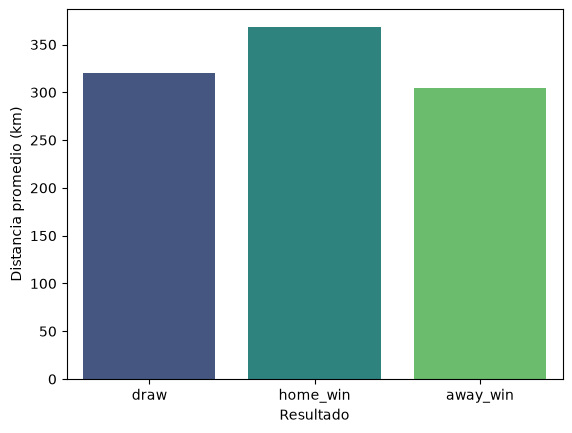

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.barplot(data=df, x='home_result', y='travel_distance_km', palette='viridis', errorbar=None)

plt.xlabel('Resultado')
plt.ylabel('Distancia promedio (km)')
plt.show()

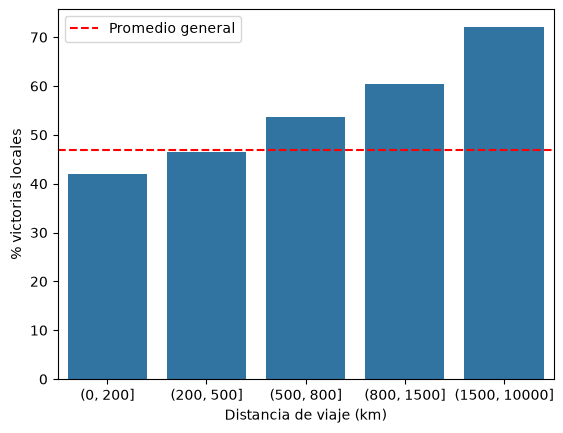

In [29]:
df['tramo'] = pd.cut(df['travel_distance_km'], [0, 200, 500, 800, 1500, 10000])
pct = (df.groupby('tramo', observed=True)['home_result']
         .apply(lambda s: (s == 'home_win').mean() * 100)
         .reset_index(name='pct_local'))

sns.barplot(data=pct, x='tramo', y='pct_local')
plt.axhline(46.9, color='red', linestyle='--', label='Promedio general')
plt.ylabel('% victorias locales')
plt.xlabel('Distancia de viaje (km)')
plt.legend()
plt.show()

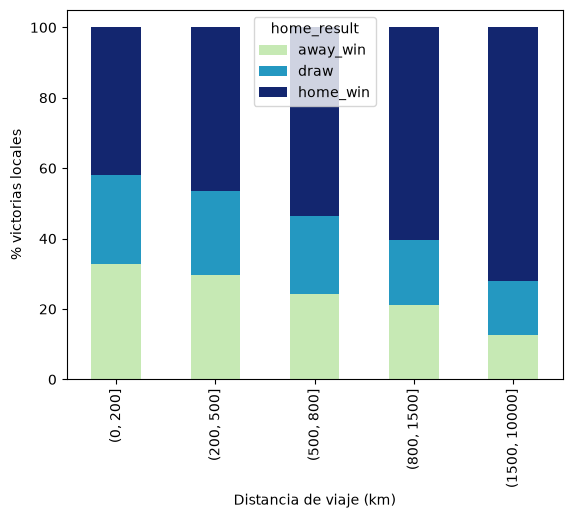

In [51]:
tabla = (df.groupby('tramo', observed=True)['home_result']
           .value_counts(normalize=True).unstack() * 100)
colores = plt.get_cmap('YlGnBu')(np.linspace(0.25, 0.95, tabla.shape[1]))
tabla.plot(kind='bar', stacked=True, color=colores)
plt.ylabel('% victorias locales')
plt.xlabel('Distancia de viaje (km)')
plt.show()

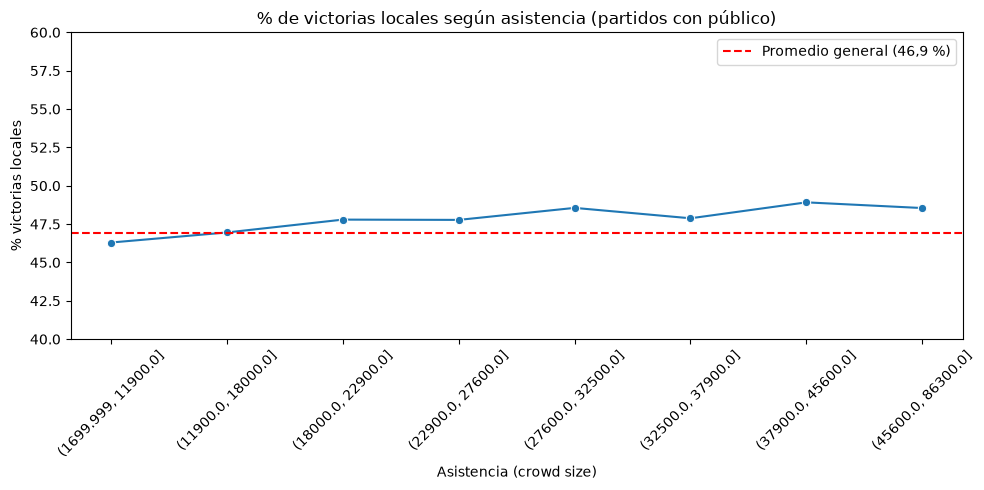

In [27]:
con_publico = df[df['crowd_size'] > 0].copy()
con_publico['tramo_crowd'] = pd.qcut(con_publico['crowd_size'], q=8)

pct_crowd = (con_publico.groupby('tramo_crowd', observed=True)['home_result']
               .apply(lambda s: (s == 'home_win').mean() * 100)
               .reset_index(name='pct_local'))
pct_crowd['tramo_crowd'] = pct_crowd['tramo_crowd'].astype(str)

plt.figure(figsize=(10, 5))
sns.lineplot(data=pct_crowd, x='tramo_crowd', y='pct_local', marker='o')
plt.axhline(46.9, color='red', linestyle='--', label='Promedio general (46,9 %)')
plt.title('% de victorias locales según asistencia (partidos con público)')
plt.xlabel('Asistencia (crowd size)')
plt.ylabel('% victorias locales')
plt.xticks(rotation=45)
plt.legend()
plt.ylim(40, 60)
plt.tight_layout()
plt.show()

In [24]:
sin_publico = df[df['crowd_size'] == 0]
print(len(sin_publico))
print(sin_publico['home_result'].value_counts(normalize=True) * 100)

9925
home_result
home_win    42.871537
away_win    32.957179
draw        24.171285
Name: proportion, dtype: float64


<Axes: xlabel='tramo_dist'>

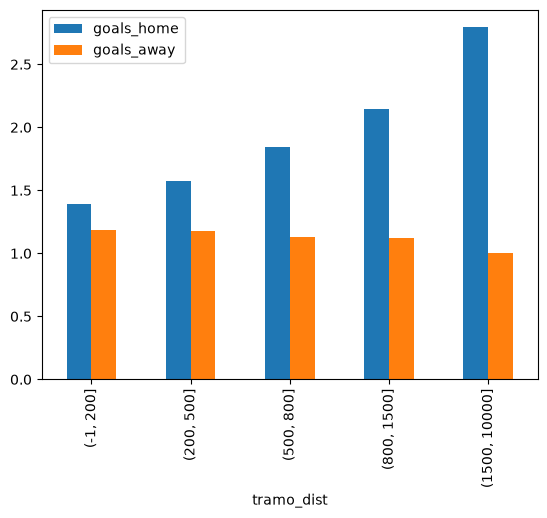

In [31]:
df.groupby('tramo_dist', observed=True)[['goals_home', 'goals_away']].mean().plot(kind='bar')

In [4]:
df.columns

Index(['match_id', 'league', 'elo_home', 'elo_away', 'elo_diff',
       'crowd_present', 'stadium_capacity', 'attendance_pct', 'crowd_size',
       'travel_distance_km', 'timezones_crossed', 'is_derby',
       'venue_familiarity', 'referee_bias_susceptibility', 'fouls_home',
       'fouls_away', 'yellow_home', 'yellow_away', 'red_home', 'red_away',
       'goals_home', 'goals_away', 'home_goal_diff', 'home_result',
       'home_points'],
      dtype='str')

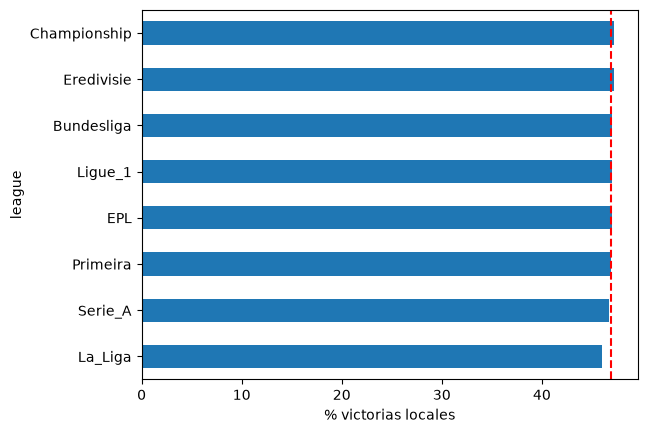

In [5]:
df['local_gana'] = (df['home_result'] == 'home_win').astype(int)
pct_liga = (df.groupby('league')['local_gana'].mean() * 100).sort_values()
pct_liga.plot(kind='barh')
plt.axvline(46.9, color='red', linestyle='--')
plt.xlabel('% victorias locales')
plt.show()

/tmp/ipykernel_21732/2767390103.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='is_derby', y='local_gana', palette='Set2')


<Axes: xlabel='is_derby', ylabel='local_gana'>

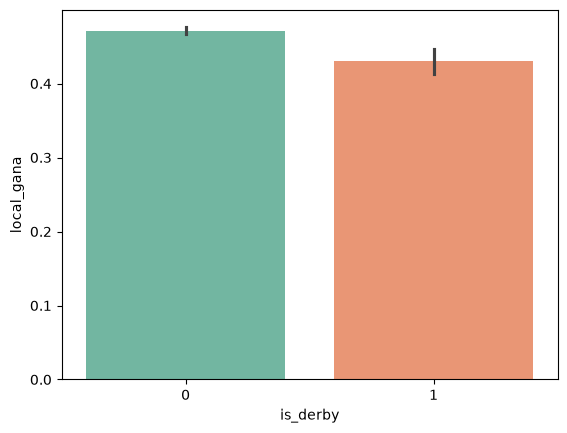

In [58]:
sns.barplot(data=df, x='is_derby', y='local_gana', palette='Set2')

In [3]:
print(df['is_derby'].value_counts())
print(df.groupby('is_derby')['home_result'].value_counts(normalize=True).unstack() * 100)

is_derby
0    46905
1     3095
Name: count, dtype: int64
home_result   away_win       draw   home_win
is_derby                                    
0            29.173862  23.720286  47.105852
1            32.471729  24.523425  43.004847


<Axes: xlabel='tramo_crowd'>

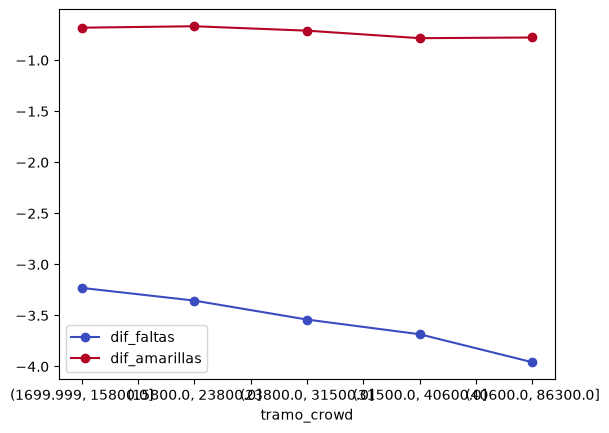

In [67]:
df['dif_faltas'] = df['fouls_home'] - df['fouls_away']
df['dif_amarillas'] = df['yellow_home'] - df['yellow_away']
df['tramo_crowd'] = pd.qcut(df.loc[df['crowd_size'] > 0, 'crowd_size'], q=5)

df[df['crowd_size'] > 0].groupby('tramo_crowd', observed=True)[['dif_faltas', 'dif_amarillas']].mean().plot(marker='o', cmap = 'coolwarm')

In [14]:
df['crowd_size'] > 0, 'crowd_size'

(0         True
 1         True
 2        False
 3         True
 4         True
          ...  
 49995     True
 49996     True
 49997     True
 49998     True
 49999     True
 Name: crowd_size, Length: 50000, dtype: bool,
 'crowd_size')

<Axes: xlabel='tramo_ocup'>

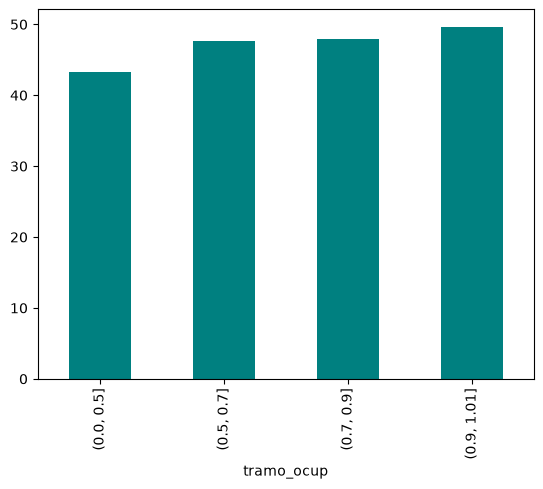

In [59]:
df['tramo_ocup'] = pd.cut(df['attendance_pct'], [0, 0.5, 0.7, 0.9, 1.01])
(df.groupby('tramo_ocup', observed=True)['local_gana'].mean() * 100).plot(kind='bar', color = 'teal')

/tmp/ipykernel_21732/1829536530.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='crowd_present', y='local_gana', palette= 'Set3')


<Axes: xlabel='crowd_present', ylabel='local_gana'>

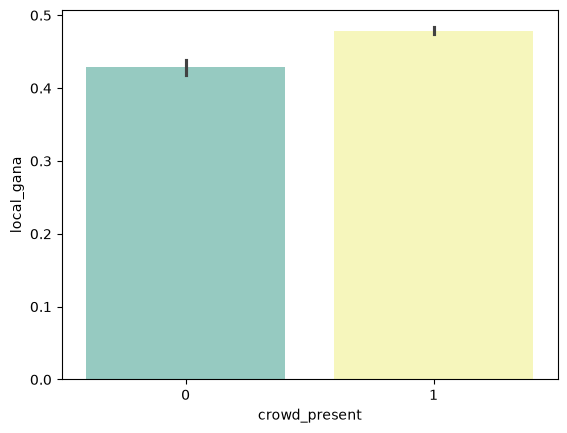

In [63]:
sns.barplot(data=df, x='crowd_present', y='local_gana', palette= 'Set3')